# Assignment 2: FrozenLake with Q-Learning

## Part A: Environment Description

FrozenLake is an 8 x 8 map where the goal is to travel from one position to the next while avoiding holes in the lake. 

The state space includes 64 possible positions to move. The action space is 4 possible actions to travel (up, down, left, right).

The actions to start will be stochastic which means that there is noise and the intended action might not happen. There will be randomness or possibility for a new action. To ensure this, is_slippery will equal True.

The reward structure consists of a reward of 1 for getting to the goal state and a reward of 0 for not reaching the goal state. The episode will terminate if the agent falls in a hole or reaches the goal state.

In [17]:
import sys
print(sys.executable)
print(sys.version)

/opt/anaconda3/envs/frozenlake_ql/bin/python
3.11.17 (main, Oct  1 2026, 20:09:52) [Clang 20.1.8 ]


In [18]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

#Create the FrozenLake environment
env = gym.make(
    "FrozenLake-v1", 
    map_name="8x8",
    is_slippery=True
)

num_states = env.observation_space.n
num_actions = env.action_space.n

print("Number of states:", num_states)
print("Number of actions:", num_actions)

Number of states: 64
Number of actions: 4


## Part B: Implement Q-Learning

The agent uses tabular Q-learning to learn the best actions to reach the goal state and receive a reward of 1. A Q-table stores the estimated values for each action at each state. 

An epsilon (e) greedy policy chooses between exploration and exploitation randomly to balance the trade-off. The Q-values are updated after each action or episode with the learning rate, discount factor, and reward 

In [19]:
# Start the Q-table with zeros for episode 1
q_table = np.zeros((num_states, num_actions))

print("Initial Q-Table shape:", q_table.shape)

Initial Q-Table shape: (64, 4)


In [41]:
#Create the function

def train_q_learning(
    alpha=0.5,
    gamma=0.99,
    epsilon=1.0,
    epsilon_decay=0.9999,
    epsilon_min=0.1,
    episodes=20000,
    seed=42
):
    rng = np.random.default_rng(seed)

    #initialize q_values with 0 to begin
    q_table = np.zeros((num_states, num_actions))
    rewards = []

    for episode in range(episodes):
        state, info = env.reset()
        total_reward = 0
        done = False

        while not done:
            #Epsilon-greedy action selection
            if rng.random() < epsilon:
                action = int(rng.integers(num_actions))
            else:
                #randomly choose the highest q_value action
                best_actions = np.flatnonzero(
                    q_table[state] == np.max(q_table[state])
                )
                action = int(rng.choice(best_actions))

            # take the action 
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # Q-learning update
            if terminated or truncated:
                target = reward
            else:
                target = reward + gamma * np.max(q_table[next_state])
            
            q_table[state, action] += alpha * (
                target - q_table[state, action]
            )

            state = next_state
            total_reward += reward

        rewards.append(total_reward)

        # diminish exploration with time
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    return q_table, rewards

In [42]:
# Train the agent 
q_table, rewards = train_q_learning()

print("Training complete")
print("Total episodes:", len(rewards))
print("Successful episodes:", sum(rewards))
print("Success rate:", sum(rewards) / len(rewards))

Training complete
Total episodes: 20000
Successful episodes: 733
Success rate: 0.03665


## Part C: Baseline Training

The baseline agent was trained for 20,000 episodes with tabular Q-learning. The states in the Q-table were initialized with zeros, and actions were determined with an epsilon-greedy policy.

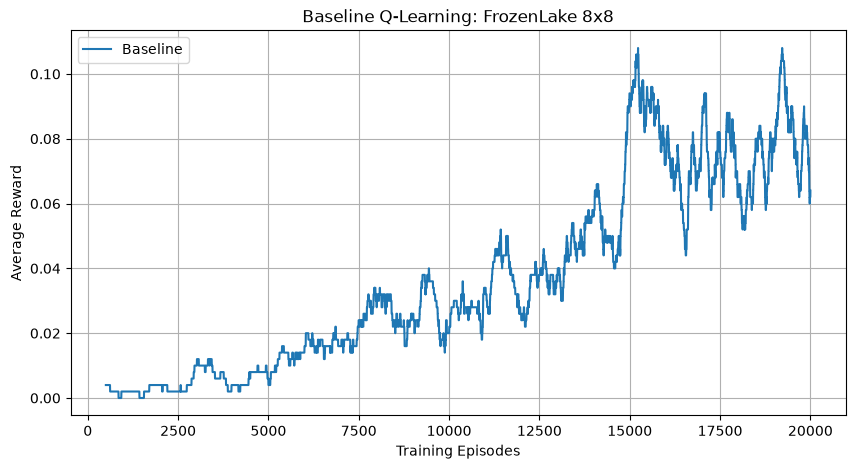

In [43]:
# moving average of rewards
window = 500

moving_avg = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

# Plot baseline training rewards
plt.figure(figsize=(10, 5))
plt.plot(
    np.arange(window, len(rewards) + 1),
    moving_avg,
    label="Baseline"
)

plt.xlabel("Training Episodes")
plt.ylabel("Average Reward")
plt.title("Baseline Q-Learning: FrozenLake 8x8")
plt.legend()
plt.grid()
plt.show()

The baseline agent had 733 successful episodes out of 20,000 episodes resulting in a 3.67% success rate. The plot shows a consistent increase in average reward with an increase in episodes or time. 

## Part D: Learning-Rate Experiment

The learning-rate experiment compares three different values of alpha (a = 0.1, 0.5, and 0.9) while the other conditions stay consistent. The experiment's purpose is to learn how the learning-rate affects the agent's training and improvement.

In [44]:
# three different learning rates
learning_rates = [0.1, 0.5, 0.9]
alpha_results = {}

for alpha in learning_rates:
    q, episode_rewards = train_q_learning(
        alpha=alpha,
        gamma=0.99,
        epsilon=0.1,
        epsilon_decay=0.9999,
        epsilon_min=0.1,
        episodes=20000,
        seed=42
    )

    alpha_results[alpha] ={
        "q_table": q,
        "rewards": episode_rewards
    }

    print(f"Alpha {alpha}: Success Rate = {np.mean(episode_rewards):.4f}")

Alpha 0.1: Success Rate = 0.2108
Alpha 0.5: Success Rate = 0.0863
Alpha 0.9: Success Rate = 0.0382


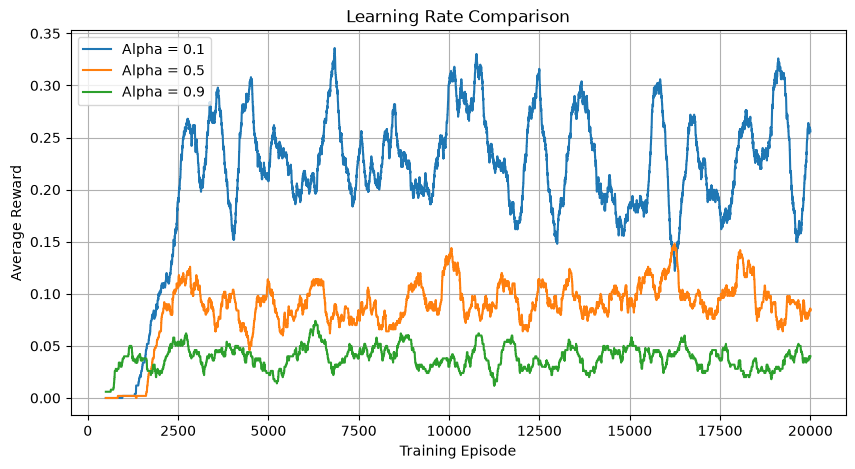

In [45]:
#plot the different learning rates
plt.figure(figsize=(10, 5))

window = 500

for alpha in learning_rates:
    episode_rewards = alpha_results[alpha]["rewards"]

    moving_avg = np.convolve(
        episode_rewards,
        np.ones(window) / window,
        mode="valid"
    )

    plt.plot(
        np.arange(window, len(episode_rewards) + 1),
        moving_avg,
        label=f"Alpha = {alpha}"
    )

plt.xlabel("Training Episode")
plt.ylabel("Average Reward")
plt.title("Learning Rate Comparison")
plt.legend()
plt.grid()
plt.show()

The learning-rate experiment showed a clear pattern of improvement in success rate with a smaller learning rate. The experiment showed that the smallest alpha rate (0.1) had the highest success rate with 21.08%. The middle alpha (0.5) had a success rate of 8.63% and the highest alpha (0.9) had the lowest success rate of 3.82%. The highest alpha had the best early learning rate as well as success rate. 

## Part E: Discount-Factor Experiment

This discount-factor experiment compares three different discount factors (0.50, 0.90, 0.99). This experiment's goal is to analyze how immediate reward vs future reward can affect success and Q-learning performance.

In [46]:
# three discount factors
discount_factors = [0.50, 0.90, 0.99]
gamma_results = {}

for gamma in discount_factors:
    q, episode_rewards = train_q_learning(
        alpha = 0.5,
        gamma = gamma,
        epsilon=1.0,
        epsilon_decay=0.9999,
        epsilon_min=0.1,
        episodes=20000,
        seed=42
    )

    gamma_results[gamma] = {
        "q_table": q,
        "rewards": episode_rewards
    }

    print(f"Gamma {gamma}: Success Rate = {np.mean(episode_rewards):.4f}")

Gamma 0.5: Success Rate = 0.0118
Gamma 0.9: Success Rate = 0.0333
Gamma 0.99: Success Rate = 0.0357


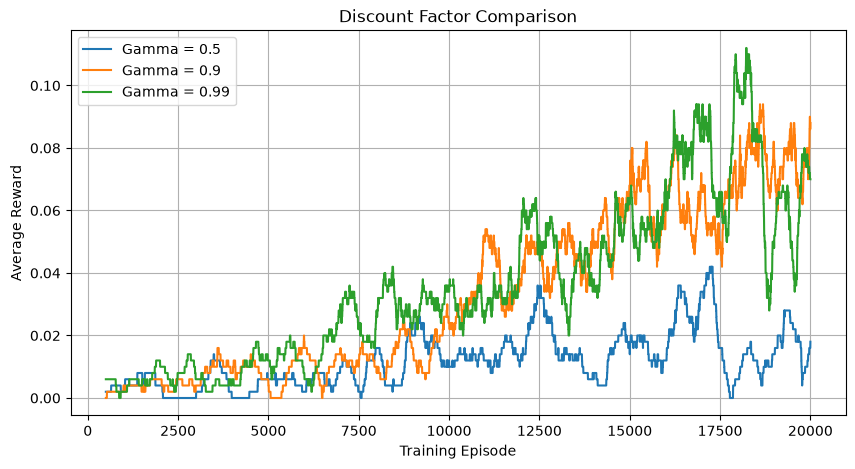

In [47]:
# plot the discount factor differences
plt.figure(figsize=(10, 5))

window = 500

for gamma in discount_factors:
    episode_rewards = gamma_results[gamma]["rewards"]

    moving_avg = np.convolve(
        episode_rewards,
        np.ones(window) / window,
        mode="valid"
    )

    plt.plot(
        np.arange(window, len(episode_rewards) + 1),
        moving_avg,
        label=f"Gamma = {gamma}"
    )

plt.xlabel("Training Episode")
plt.ylabel("Average Reward")
plt.title("Discount Factor Comparison")
plt.legend()
plt.grid()
plt.show()

The discount-factor experiment showed a noticeable pattern of an increase in success with an increase of the discount factor. The highest discount factor (0.99)had a success rate of 3.57% while the middle discount factor (0.9) shows a success rate of 3.33% and the lowest discount factor (0.50) shows a success rate of 1.18%.

## Part F: Additional Hyperparameter: Epsilon-Decay

This experiment compares three different epsilon-decay values. The goal is to analyze if decreasing exploration will improve success rate and Q-learning.

In [48]:
# three epsilon-decay values
decay_values = [0.999, 0.9995, 0.9999]
decay_results = {}

for decay in decay_values:
    q, episode_rewards = train_q_learning(
        alpha = 0.5,
        gamma = 0.99,
        epsilon=1.0,
        epsilon_decay=decay,
        epsilon_min=0.1,
        episodes=20000,
        seed=42
    )

    decay_results[decay] = {
        "q_table": q,
        "rewards": episode_rewards
    }

    print(f"Decay {decay}: Success Rate = {np.mean(episode_rewards):.4f}")

Decay 0.999: Success Rate = 0.0894
Decay 0.9995: Success Rate = 0.0854
Decay 0.9999: Success Rate = 0.0370


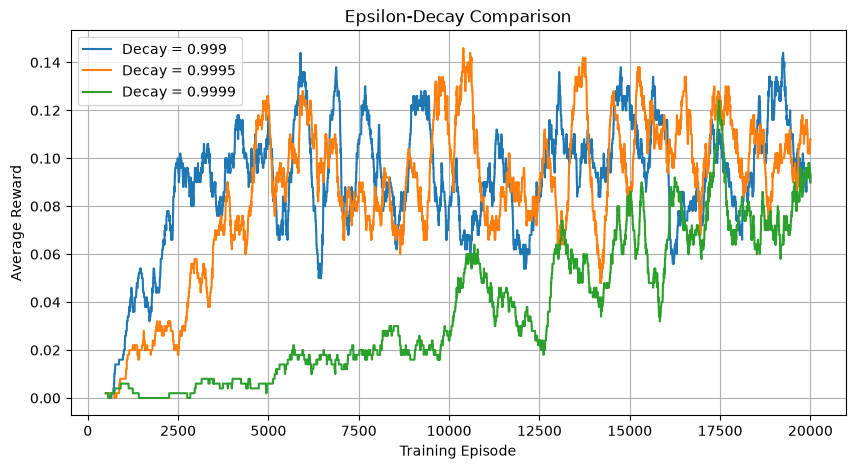

In [49]:
# plot the three epsilon-decay values
plt.figure(figsize=(10, 5))

window = 500

for decay in decay_values:
    episode_rewards = decay_results[decay]["rewards"]

    moving_avg = np.convolve(
        episode_rewards,
        np.ones(window) / window,
        mode="valid"
    )

    plt.plot(
        np.arange(window, len(episode_rewards) + 1),
        moving_avg,
        label=f"Decay = {decay}"
    )

plt.xlabel("Training Episode")
plt.ylabel("Average Reward")
plt.title("Epsilon-Decay Comparison")
plt.legend()
plt.grid()
plt.show()


The epsilon-decay experiment showed that a lower decay rate of 0.999 had the highest success rate at 8.94%, followed by 0.9995 at 8.54% and 0.9999 at 3.70%. The graph shows that faster epsilon decay helped the agent achieve rewards earlier in training, while slower decay resulted in more gradual improvement. This suggests that reducing exploration earlier was more effective for this experiment.

## Part G: Evaluate Best Agent

I will train a mix of hyperparameters from each experiment to evaluate the best agent. I will analyze this setting trained with 100 episodes without exploration to measure performance.

In [50]:
# evaluate the best agent without exploration
best_q_table, best_rewards = train_q_learning(
    alpha=0.1,
    gamma=0.99,
    epsilon=1.0,
    epsilon_decay=0.999,
    epsilon_min=0.1,
    episodes=20000,
    seed=42
)

print("Training complete")
print("Training success rate:", np.mean(best_rewards))

Training complete
Training success rate: 0.21345


In [51]:
# Evaluate the best agent without exploration
eval_rewards = []
eval_steps = []

for episode in range(100):
    state, info = env.reset()
    done = False
    total_reward = 0
    steps = 0

    while not done:
        action = int(np.argmax(best_q_table[state]))

        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        total_reward += reward
        steps += 1
        state = next_state

    eval_rewards.append(total_reward)
    eval_steps.append(steps)

print("Evaluation Complete")
print("Mean Reward:", np.mean(eval_rewards))
print("Success Rate:", np.mean(eval_rewards))
print("Average Steps:", np.mean(eval_steps))

Evaluation Complete
Mean Reward: 0.5
Success Rate: 0.5
Average Steps: 66.63


The best agent was trainged using a learning rate of 0.1, discount factor of 0.99, and epsilon_decay of 0.999. During training, the agent achieved a success rate of 21.345%. When evaluated over 100 episodes without exploration, the agent achieved a mean reward of 0.5, a success rate of 50%, and an average of 66.63 steps per episode.

The evaluation success rate was higher than the training success rate because the agent was no longer selecting random actions for exploration. This shows that the agent learned a policy that could reach the goal, although it was not successful in every episode.

## Video Implementation

In [52]:
%pip install imageio imageio-ffmpeg

Note: you may need to restart the kernel to use updated packages.


In [53]:
# video implementation

import gymnasium as gym
import numpy as np
import imageio

video_env = gym.make(
    "FrozenLake-v1",
    map_name="8x8",
    is_slippery=True,
    render_mode="rgb_array"
)

frames = []
state, info = video_env.reset()

done = False
steps = 0

while not done and steps < 200:
    frames.append(video_env.render())

    action = np.argmax(best_q_table[state])
    state, reward, terminated, truncated, info = video_env.step(action)

    done = terminated or truncated
    steps += 1

frames.append(video_env.render())

imageio.mimsave(
    "frozenlake_agent.mp4",
    frames,
    fps=5
)

video_env.close()

print("Video saved as frozenlake_agent.mp4")
print("Reward:", reward)
print("Steps:", steps)

Video saved as frozenlake_agent.mp4
Reward: 0
Steps: 100
